# Build Sol Dataset

## Install necessary libraries from python

In [1]:
# DGL must be a CUDA build matching the installed PyTorch, otherwise graphs cannot be moved to the GPU
# (the PyPI "dgl" package is CPU-only). For PyTorch 2.4 + CUDA 12.1:
#   !pip install dgl -f https://data.dgl.ai/wheels/torch-2.4/cu121/repo.html
# or, when data.dgl.ai is unreachable:  conda install -c dglteam/label/th24_cu121 dgl
import torch, dgl
assert torch.cuda.is_available(), "No CUDA device visible to PyTorch"
dgl.graph(([0], [0])).to("cuda")   # raises here if DGL is a CPU-only build
print("torch", torch.__version__, "| dgl", dgl.__version__, "|", torch.cuda.get_device_name(0))


/tmp/claude-1009/-home-cuongpd-GraphFusionVulDetect/99c759be-05c4-4a6a-8b9c-ebc43a624c33/scratchpad/gpuenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.4.0+cu121 | dgl 2.4.0+cu121 | NVIDIA L40S


In [2]:
# Slither is not needed here: the call graphs are already in assets/datasets (*.fcg).
# Needs: networkx, scikit-learn, pandas, matplotlib, tqdm and transformers (4.x works with PyTorch 2.4).
#   !pip install -q networkx "transformers<5"


## Import Python libraries

In [3]:
from concurrent.futures import ThreadPoolExecutor
from random import sample
import json
import multiprocessing
import traceback
import pandas as pd
import os
from pathlib import Path
import networkx as nx
# import pygraphviz as pgv
import matplotlib.pyplot as plt
import dgl
import os
import shutil
import random
from typing import Tuple, Optional, Dict
from copy import deepcopy
from pathlib import Path
import glob
from multiprocessing import Pool as ThreadPool
from functools import partial
import torch.nn as nn
import torch
from torch import Tensor
import torch.nn.functional as F
from dgl.nn import GraphConv, GATConv, TAGConv, SAGEConv, GINConv
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import pandas as pd
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from dgl.nn.pytorch import Sequential
import pickle
import random
import numpy as np
from tqdm import tqdm
from dgl.data import DGLDataset
from dgl.dataloading import GraphDataLoader
os.environ["TORCH_DYNAMO_DISABLE"] = "1"

def seed_everything(seed: int):
    # Hàm đặt seed cố định cho tất cả các thư viện để kết quả có thể tái tạo lại được
    import random, os
    import numpy as np
    import torch
    
    random.seed(seed)  # Cố định seed cho thư viện random
    # os.environ['PYTHONHASHSEED'] = str(seed)  # Cố định hash seed của Python
    np.random.seed(seed)  # Cố định seed cho NumPy
    torch.manual_seed(seed)  # Cố định seed cho PyTorch CPU
    torch.cuda.manual_seed(seed)  # Cố định seed cho PyTorch GPU
    torch.backends.cudnn.deterministic = True  # Đảm bảo tính nhất quán của thuật toán cuDNN
    torch.backends.cudnn.benchmark = True  # Tối ưu hóa tốc độ tính toán

seed_everything(42)

# Functions

In [4]:
def plot(x: list, y: list):
    x = np.array(x)
    y = np.array(y)

    plt.plot(x, y)
    plt.title("Decrease of loss over epochs")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.show()

In [5]:
def readData(path: str, n_scam: int):
    dic = {
        "filename": [],
    }
    cnt0, cnt1 = 0, 0
    for label in ["Vulnerable_Fcg"]:
        for file in sorted(os.listdir(path + "/" + label)):
            if file.endswith(".fcg"):
                if cnt1 < n_scam:
                    dic['filename'].append("/".join([path, label, file]))
                    cnt1 += 1
    df = pd.DataFrame(dic)
    return df

In [6]:
import csv, json
from transformers import RobertaModel, RobertaTokenizer

# Which vulnerability to train. The timestamp checkpoint already exists
# (src/infrastructure/analysis_model/best_node_classifier_model.pt), so only reentrancy is trained.
VULN = "Reentrancy"
ENCODERS = {"Reentrancy": "Quangnguyen711/codebert-solidity-re-entrancy",
            "TimestampDependency": "Quangnguyen711/codebert-solidity-time-dep"}
HAS_SYNTAX = {"Reentrancy": lambda code: "call.value" in code,
              "TimestampDependency": lambda code: "block.timestamp" in code or "now" in code}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "assets/datasets").exists())
# Full dataset (Kaggle archive), graphs built by scripts/train_reentrancy_gfd.py build with the API's own converter and
# encoder, so their stored featuresH is already what /analyze computes. The older graphs under SourceCodeSyntaxDataset
# carry embeddings from another encoder: point DATASET_DIR there only with REEMBED = True.
DATASET_DIR = REPO / "assets/datasets/SourceCodeSyntaxDatasetFull"
REEMBED = False

if REEMBED:
    tokenizer = RobertaTokenizer.from_pretrained(ENCODERS[VULN])
    encoder = RobertaModel.from_pretrained(ENCODERS[VULN]).to(DEVICE).eval()

def embed(code: str) -> torch.Tensor:
    """[CLS] embedding, exactly as the API computes it (embedding_generator.get_embeddings)."""
    inputs = tokenizer(code, return_tensors="pt", truncation=True, padding=True).to(DEVICE)
    with torch.no_grad():
        return encoder(**inputs).last_hidden_state[:, 0, :].squeeze().cpu()

# Function-level ground truth shipped with the repo (label 1 = vulnerable function).
csv.field_size_limit(10 ** 9)
squash = lambda code: "".join(code.split())
VULNERABLE_FUNCTIONS = {squash(r["function"]) for split in ("train", "test")
                        for r in csv.DictReader(open(REPO / f"assets/datasets/FunctionSyntaxDataset/{VULN}Dataset/{split}.csv", encoding="utf-8", errors="replace"))
                        if r["label"] == "1"}

def loadfeatureGraph(path):
    """
    path: path to fcg file
    return: dgl.DGLGraph with 'featuresH' and 'node_label', number of functions holding the syntax

    The .fcg files in the repo have no 'node_label' and their mapping has no agent 'reason', and their stored
    embeddings come from another encoder. So:
      - featuresH is recomputed with the encoder the API uses when REEMBED is set;
      - a contract with exactly one function holding the syntax gets that function labelled 1 (the rule this
        notebook already applied); otherwise the labels come from FunctionSyntaxDataset.
    """
    g = dgl.load_graphs(path)[0][0]
    info = json.load(open(path.replace(".fcg", "_mapping.json"), "r", encoding="utf-8"))
    code = {idx: info["code"].get(name, "") for name, idx in info["node"].items()}
    n = g.num_nodes()
    syntax = [int(HAS_SYNTAX[VULN](code.get(i, ""))) for i in range(n)]
    labels = syntax if sum(syntax) == 1 else [int(squash(code.get(i, "")) in VULNERABLE_FUNCTIONS) for i in range(n)]
    if REEMBED:
        g.ndata["featuresH"] = torch.stack([embed(code.get(i, "")) for i in range(n)])
    g.ndata["node_label"] = torch.tensor(labels)
    return g, sum(syntax)


def createBatchMulThread(data, max_works):
    """
    data: Graph paths (max_works is kept for compatibility; embedding runs on one GPU)
    return list[DGLGraph] that have at least one vulnerable function
    """
    loaded = [loadfeatureGraph(p) for p in tqdm(data, desc="Loading graphs")]
    goodgraphs = [g for g, _ in loaded if int(g.ndata["node_label"].sum()) >= 1]
    print(f"Contracts with exactly one syntax function: {sum(c == 1 for _, c in loaded)} / {len(loaded)}")
    print(f"Contracts kept (at least one vulnerable function): {len(goodgraphs)} / {len(loaded)}")
    print(f"Functions: {sum(g.num_nodes() for g in goodgraphs)}, vulnerable: {sum(int(g.ndata['node_label'].sum()) for g in goodgraphs)}")
    return goodgraphs


In [7]:
# g = loadfeatureGraph("/kaggle/input/ngclassificationtime/SmartContractVulnerabilityDetection/SourceCodeSyntaxDataset/TimestampDependencyDataset/Test/Vulnerable_Fcg/0x051fda7486480dd5abcf5dd742ef002a2ebb9ea0.fcg")
# print(g.ndata['node_label'].tolist())

# file_path_split = "/kaggle/input/ngclassificationtime/SmartContractVulnerabilityDetection/SourceCodeSyntaxDataset/TimestampDependencyDataset/Test/Vulnerable_Fcg/0x051fda7486480dd5abcf5dd742ef002a2ebb9ea0.fcg".split("/")
# print(file_path_split)
# info_path = "/".join(file_path_split[:-1]) + "/" + file_path_split[-1].replace(".fcg", "_mapping.json")
# print(info_path)
# info_data = json.load(open(info_path, "r"))

# new_node_label = []
# for name, reason in info_data['reason'].items():
#     if "Not vulnerable:" not in reason and "No reason provided" not in reason:
#         new_node_label.append(1)
#     else:
#         new_node_label.append(0)

# print(new_node_label)

# g.ndata['node_label'] = torch.tensor(new_node_label)

# print(g.ndata['node_label'])

# Model GNNs

In [8]:
def get_convolution_layer(
        input_dimension: int,
        output_dimension: int,
        name: list,
        agg_hidden_dimension: int = 1024, # Only use for GINConv
        heads: int = 0 # Only use for GATConv
) -> Optional[nn.Module]:
    mlp, gin_agg, sage_agg = None, 'sum', 'mean'
    if name[0] == "GIN":
        mlp = nn.Sequential()
        mlp.append(nn.Linear(input_dimension, agg_hidden_dimension))
        mlp.append(nn.ReLU())
        mlp.append(nn.Linear(agg_hidden_dimension, output_dimension))
        gin_agg = name[1]

    if name[0] == "SAGE":
        sage_agg = name[1]

    return {"GCN": GraphConv(input_dimension, output_dimension, activation=F.relu),
            "SAGE": SAGEConv(input_dimension, output_dimension, activation=F.relu, norm=F.normalize, aggregator_type=sage_agg),
            "GAT": GATConv(input_dimension, output_dimension, num_heads=heads, activation=F.relu, feat_drop=0.0, attn_drop=0.0),
            "TAG": TAGConv(input_dimension, output_dimension, k=4, activation=F.relu),
            "GIN": GINConv(apply_func=mlp, activation=F.relu, aggregator_type=gin_agg)
            }.get(name[0], None)

class NodeClassifierGNN(nn.Module):
    def __init__(self, mtype, infeats, hfeats: list, fc1_layer, fc2_layer, outclass, ginfeat=None):
        super(NodeClassifierGNN, self).__init__()
        self.mtype = mtype
        self.hfeats = hfeats
        self.device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

        # Define convolutional layers
        self.conv_layers = nn.ModuleList()
        current_dim = infeats
        
        for i, hdim in enumerate(hfeats):
            if mtype[0] == "GAT":
                # For GAT, the output dimension is hdim * num_heads
                num_heads = 8 if i < len(hfeats) -1 else 1 # Last layer with 1 head
                conv = get_convolution_layer(current_dim, hdim, name=mtype, heads=num_heads)
                current_dim = hdim * num_heads
            else:
                conv = get_convolution_layer(current_dim, hdim, name=mtype, agg_hidden_dimension=ginfeat if mtype[0] == "GIN" else None)
                current_dim = hdim
            self.conv_layers.append(conv)
            
        # Classifier layers
        self.fc1 = nn.Linear(current_dim, fc1_layer)
        self.fc2 = nn.Linear(fc1_layer, fc2_layer)
        self.fc3 = nn.Linear(fc2_layer, outclass)

        nn.init.xavier_uniform_(self.fc1.weight)
        nn.init.xavier_uniform_(self.fc2.weight)
        nn.init.xavier_uniform_(self.fc3.weight)

    def forward(self, g, infeats):
        h = infeats
        for i, layer in enumerate(self.conv_layers):
            h = layer(g, h)
            if self.mtype[0] == "GAT":
                # Reshape from [num_nodes, num_heads, out_dim] to [num_nodes, num_heads * out_dim]
                h = h.reshape(h.shape[0], -1)
        
        # Node-level features are now ready for classification
        # No pooling is applied
        
        ans = self.fc1(h)
        ans = F.relu(ans)
        ans = self.fc2(ans)
        ans = F.relu(ans)
        return self.fc3(ans)

    def save(self, path):
        torch.save(self.state_dict(), path)

    def load(self, path):
        self.load_state_dict(torch.load(path))

# Training

In [9]:
class GraphDataset(DGLDataset):
    def __init__(self, graphs):
        super().__init__(name='graph_dataset')
        self.graphs = graphs

    def __getitem__(self, idx):
        # Return the graph itself. The labels are part of the graph object.
        return self.graphs[idx]

    def __len__(self):
        return len(self.graphs)

In [10]:
# Add this import at the top
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix


def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def train_and_eval(dataloader, tdataloader, mtype, s_epoch, e_epoch, n_feats, hfeats, outclass, ginfeat, save_path=None):
    seed_everything(42)
    # Use the new NodeClassifierGNN model
    model = NodeClassifierGNN(mtype=mtype, infeats=n_feats, hfeats=hfeats, fc1_layer=256, fc2_layer=64, outclass=outclass, ginfeat=ginfeat)
    model.to(model.device)
    print(model)
    
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = torch.nn.CrossEntropyLoss()

    result = {
        "loss": [],
        "val_acc": [],
        "val_f1": [],
        "epoch": []
    }

    for epoch in tqdm(range(s_epoch, e_epoch), desc="Training Epochs"):
        model.train()
        total_loss = 0
        all_preds = []
        all_labels = []

        for batched_graph in dataloader:
            batched_graph = batched_graph.to(model.device)
            feats = batched_graph.ndata['featuresH'].float()
            # Get node labels from the graph
            labels = batched_graph.ndata['node_label'].long()
            
            pred = model(batched_graph, feats)
            loss = criterion(pred, labels)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
            
            preds_batch = pred.argmax(dim=1)
            all_preds.extend(preds_batch.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

        epoch_loss = total_loss / len(dataloader)
        epoch_acc = accuracy_score(all_labels, all_preds)
        result['loss'].append(epoch_loss)
        result['epoch'].append(epoch)
        # print(f"Epoch: {epoch} | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc*100:.4f}%")
        
        # Evaluation
        model.eval()
        with torch.no_grad():
            tpred, tlabel = [], []
            for tbatched_graph in tdataloader:
                tbatched_graph = tbatched_graph.to(model.device)
                tfeats = tbatched_graph.ndata['featuresH'].float()
                tlabels = tbatched_graph.ndata['node_label'].long()
                
                out = model(tbatched_graph, tfeats)
                preds = out.argmax(dim=1)
                
                tpred.extend(preds.cpu().numpy())
                tlabel.extend(tlabels.cpu().numpy())

            if epoch == e_epoch - 1:
                print("\n" + "="*50)
                print("                Validation Results")
                print("="*50)
    
                # Generate and print the classification report
                # This is the most important output for an imbalanced dataset!
                report = classification_report(tlabel, tpred, target_names=['Class 0 (Non-Vul)', 'Class 1 (Vul)'])
                print(report)
                
                # For a better visual, display the confusion matrix
                cm = confusion_matrix(tlabel, tpred)
                disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Vul', 'Vul'])
                disp.plot(cmap=plt.cm.Blues)
                plt.title("Confusion Matrix")
                plt.show()
            
            val_acc = accuracy_score(tlabel, tpred)
            val_f1 = f1_score(tlabel, tpred, average='weighted')
            val_precision = precision_score(tlabel, tpred, average='weighted')
            val_recall = recall_score(tlabel, tpred, average='weighted')
            
            result['val_acc'].append(val_acc)
            result['val_f1'].append(val_f1)
            
            # print(f'Val Accuracy: {val_acc * 100:.2f}%')
            # print(f'Val F1 Score: {val_f1 * 100:.2f}%')
            # print(f'Val Precision: {val_precision * 100:.2f}%')
            # print(f'Val Recall: {val_recall * 100:.2f}%')

    print("\n--- Plotting Results ---")
    print("Loss vs. Epochs")
    plot(result["epoch"], result["loss"])
    print("Validation Accuracy vs. Epochs")
    plot(result["epoch"], result["val_acc"])
    print("Validation F1-Score vs. Epochs")
    plot(result["epoch"], result["val_f1"])
    
    if save_path:
        model.save(save_path)   # last epoch; the test split is not used to pick it
        print(f"Saved {save_path}")
    return result

Loading graphs:   0%|          | 0/275 [00:00<?, ?it/s]

Loading graphs:  72%|███████▏  | 198/275 [00:00<00:00, 1978.21it/s]

Loading graphs: 100%|██████████| 275/275 [00:00<00:00, 2068.37it/s]

Contracts with exactly one syntax function: 208 / 275
Contracts kept (at least one vulnerable function): 213 / 275
Functions: 8413, vulnerable: 214
Train Graph Count: 213


Loading graphs:   0%|          | 0/71 [00:00<?, ?it/s]

Loading graphs: 100%|██████████| 71/71 [00:00<00:00, 2005.79it/s]

... (49 outputs left out)

Training Epochs:  94%|█████████▍| 47/50 [02:35<00:11,  3.83s/it]

Training Epochs:  96%|█████████▌| 48/50 [02:39<00:07,  3.88s/it]

Training Epochs:  98%|█████████▊| 49/50 [02:43<00:03,  3.78s/it]


                Validation Results
                   precision    recall  f1-score   support

Class 0 (Non-Vul)       1.00      1.00      1.00      1912
    Class 1 (Vul)       0.90      0.95      0.92        58

         accuracy                           1.00      1970
        macro avg       0.95      0.97      0.96      1970
     weighted avg       1.00      1.00      1.00      1970



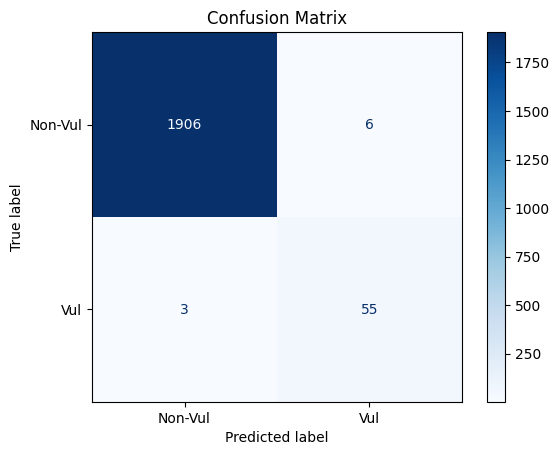

Training Epochs: 100%|██████████| 50/50 [02:47<00:00,  3.82s/it]

Training Epochs: 100%|██████████| 50/50 [02:47<00:00,  3.34s/it]


--- Plotting Results ---
Loss vs. Epochs


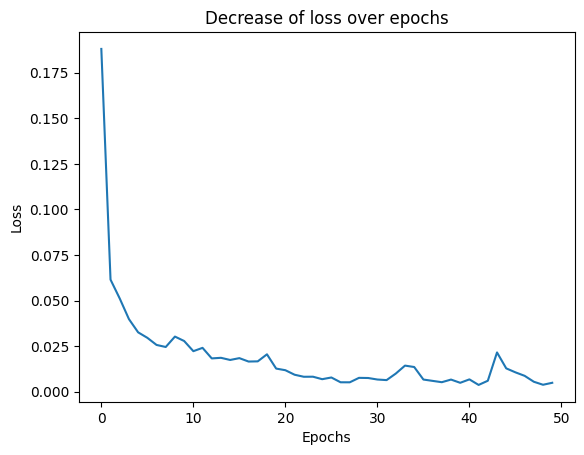

Validation Accuracy vs. Epochs


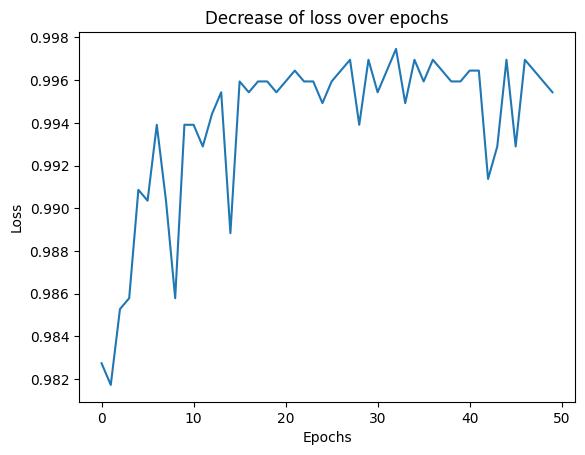

Validation F1-Score vs. Epochs


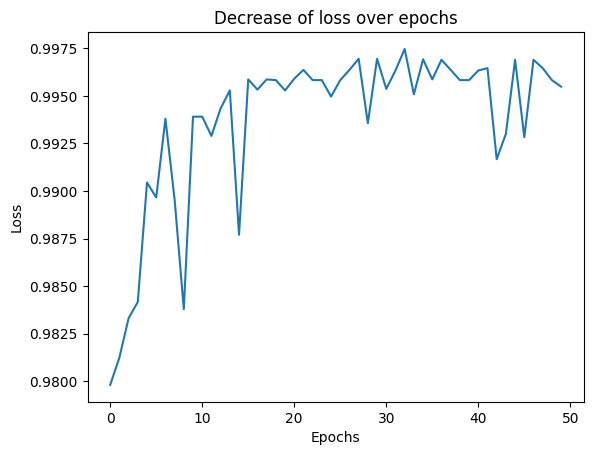

Saved /home/cuongpd/GraphFusionVulDetect/src/infrastructure/analysis_model/best_node_classifier_model_reentrancy.pt


In [11]:
# --- Main Execution ---

# For demonstration, let's assume `g.ndata["node_labels"]` exists and has `num_classes` unique values.
# You need to ensure your graph creation process correctly adds these labels.
# For example:
# g = dgl.graph(...)
# g.ndata['features'] = torch.randn(g.num_nodes(), 773)
# g.ndata['node_labels'] = torch.randint(0, num_classes, (g.num_nodes(),))
# dgl.save_graphs("path/to/graph.fcg", [g])

# NOTE: The original `readData` function might not be fully representative of a node classification task,
# as it assigns a single label per graph. The core logic change assumes node labels are loaded with the graph.

data_path = str(DATASET_DIR / f"{VULN}Dataset")
save_path = str(REPO / "src/infrastructure/analysis_model/best_node_classifier_model_reentrancy.pt")

# This part might need adjustment based on how you structure your train/test split for node classification.
# Often for node classification, you work with a single large graph and use node masks for train/val/test splits.
# However, if you have many small graphs, this approach is fine.
train_df = readData(f"{data_path}/Train", 1000) # Using a smaller number for faster demo
test_df = readData(f"{data_path}/Test", 600)


# Load graphs
# Ensure your loaded graphs have g.ndata["node_labels"]
graphs = createBatchMulThread(train_df['filename'].tolist(), 16)
print(f"Train Graph Count: {len(graphs)}")
graphs = [dgl.add_self_loop(g) for g in graphs]
dataset = GraphDataset(graphs)
dataloader = GraphDataLoader(dataset, batch_size=32, drop_last=False, shuffle=True)

tgraphs = createBatchMulThread(test_df['filename'].tolist(), 16)
print(f"Test Graph Count: {len(tgraphs)}")
tgraphs = [dgl.add_self_loop(g) for g in tgraphs]
tdataset = GraphDataset(tgraphs)
tdataloader = GraphDataLoader(tdataset, batch_size=128, drop_last=False, shuffle=False)

# Parameters
n_feats = graphs[0].ndata['featuresH'].shape[1]
# Determine the number of classes from the node labels in your data
# This is a placeholder; you must set this value based on your dataset
try:
    # Check the number of unique labels in the first graph's node_labels
    num_classes = len(torch.unique(graphs[0].ndata['node_label']))
    print(f"Detected {num_classes} classes for node classification.")
except KeyError:
    print("Error: `g.ndata['node_label']` not found in the graph.")
    print("Please ensure your graphs are saved with node-level labels.")
    num_classes = 2 # Defaulting to 2 for now
    

# Run training and evaluation
result = train_and_eval(
    dataloader=dataloader, 
    tdataloader=tdataloader, 
    mtype=['GAT', ''], # Example: Using GAT
    s_epoch=0, 
    e_epoch=50, # Reduced epochs for demo
    n_feats=n_feats,
    hfeats=[256, 128], # Hidden layer dimensions
    outclass=num_classes, # Number of node classes
    ginfeat=1024,
    save_path=save_path
)

In [12]:
# Timestamp dependency: not retrained. src/infrastructure/analysis_model/best_node_classifier_model.pt is the
# timestamp node model (checked: F1 0.90 on one-syntax timestamp contracts with codebert-solidity-time-dep).
# To retrain it, set VULN = "TimestampDependency" above and change save_path.


In [13]:
# (removed: "pip install --upgrade torch torchvision" replaces the PyTorch build DGL was compiled for)
